In [1]:
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import AveragePooling2D
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Input
from tensorflow.keras.models import Model
from keras.models import Sequential

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

import matplotlib.pyplot as plt
import numpy as np
import random
import cv2
import os

In [2]:
from imutils import paths


In [3]:
imagePaths = sorted(list(paths.list_images(r'/home/smartcity_sp7/praveen/save_3_classes_data')))

# random shuffle
random.seed(42)
random.shuffle(imagePaths)

data = []
labels = []
image_dims = (224, 224, 3)

for imagePath in imagePaths:
    image = cv2.imread(imagePath)
    image = cv2.resize(image, (image_dims[1], image_dims[0]))
    image = img_to_array(image)
    data.append(image)
    l = label = imagePath.split(os.path.sep)[-2].split("_")
    labels.append(l)

data = np.array(data, dtype="float") / 255.0
labels = np.array(labels)
print("{} images ({:.2f}MB)".format(len(imagePaths), data.nbytes / (1024 * 1000.0)))

954 images (1121.90MB)


In [4]:
data = np.array(data)
label = np.array(labels)
print(data.shape)

(954, 224, 224, 3)


In [5]:
mlb = MultiLabelBinarizer()
labels = mlb.fit_transform(labels)
# total 4 labels
print("class labels:")
for (i, label) in enumerate(mlb.classes_):
    print("{}. {}".format(i + 1, label))

class labels:
1. AK
2. BCC
3. SK


In [6]:
def MobileNetV2_model(learning_rate, input_shape,class_number):
    baseModel = MobileNetV2(include_top=False, input_tensor=Input(shape=input_shape))
    for layer in baseModel.layers[:-4]:
        layer.trainable = False

    model = Sequential()
    model.add(baseModel)
    model.add(AveragePooling2D(pool_size=(2, 2)))
    model.add(Flatten())
    model.add(Dense(512, activation="relu"))
    model.add(Dropout(0.5))
    model.add(Dense(50, activation="relu"))
    model.add(Dropout(0.5))
    model.add(Dense(class_number, activation='softmax'))

    return model

In [7]:
bs = 32
lr = 0.0001
size = (224, 224)
shape = (224,224, 3)
epochs = 10
class_number = 3

In [8]:
model = MobileNetV2_model(lr,shape,class_number)
model.compile(loss= "categorical_crossentropy", metrics=["accuracy"], optimizer="adam")

In [9]:
trainX, testX, trainY, testY = train_test_split(data, labels, test_size=0.20)

In [10]:
print("[INFO] training ...")
H = model.fit(trainX, trainY, batch_size=32,steps_per_epoch=len(trainX) // 32,	validation_data=(testX, testY),	validation_steps=len(testX) // 32,	epochs=50)

[INFO] training ...
Epoch 1/50
23/23 [==============================] - 20s 513ms/step - loss: 2.6280 - accuracy: 0.4130 - val_loss: 0.9501 - val_accuracy: 0.5625
Epoch 2/50
23/23 [==============================] - 9s 375ms/step - loss: 1.2305 - accuracy: 0.4884 - val_loss: 1.0494 - val_accuracy: 0.4500
Epoch 3/50
23/23 [==============================] - 8s 370ms/step - loss: 1.0655 - accuracy: 0.5185 - val_loss: 0.9319 - val_accuracy: 0.5688
Epoch 4/50
23/23 [==============================] - 9s 374ms/step - loss: 0.9574 - accuracy: 0.5636 - val_loss: 0.9056 - val_accuracy: 0.6375
Epoch 5/50
23/23 [==============================] - 9s 379ms/step - loss: 0.8815 - accuracy: 0.5869 - val_loss: 0.8595 - val_accuracy: 0.6250
Epoch 6/50
23/23 [==============================] - 9s 372ms/step - loss: 0.8590 - accuracy: 0.6471 - val_loss: 0.9495 - val_accuracy: 0.6313
Epoch 7/50
23/23 [==============================] - 9s 380ms/step - loss: 0.6496 - accuracy: 0.6881 - val_loss: 0.9864 - val_ac

In [11]:
model.save_weights(r'/home/smartcity_sp7/praveen/W_E_I_G_H_T_S/mobilevnetv2_save_weights')

In [12]:
# prompt: print classification report

print("[INFO] evaluating network...")
predictions = model.predict(testX, batch_size=bs)
print(classification_report(testY.argmax(axis=1),
	predictions.argmax(axis=1), target_names=mlb.classes_))


[INFO] evaluating network...
6/6 [==============================] - 2s 287ms/step
              precision    recall  f1-score   support

          AK       0.68      0.63      0.65        57
         BCC       0.72      0.82      0.76        71
          SK       0.82      0.75      0.78        63

    accuracy                           0.74       191
   macro avg       0.74      0.73      0.73       191
weighted avg       0.74      0.74      0.74       191



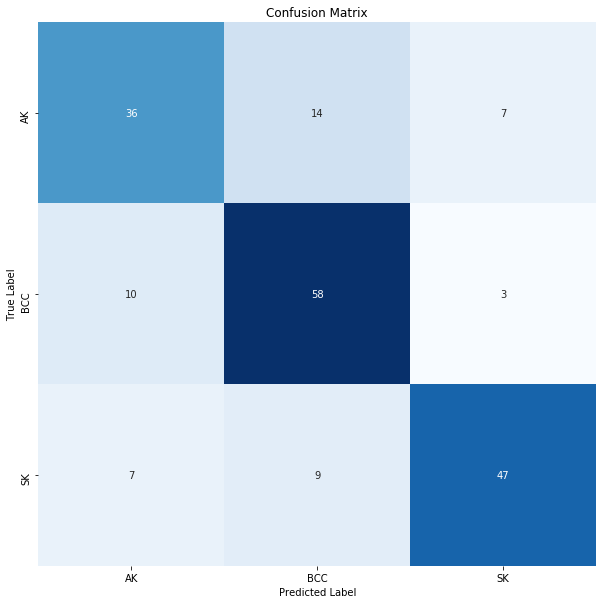

In [13]:
# prompt: print confusion matrix as heatmap

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

# compute the confusion matrix
cm = confusion_matrix(testY.argmax(axis=1), predictions.argmax(axis=1))

# plot the confusion matrix as a heatmap
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=mlb.classes_, yticklabels=mlb.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()
